# Labjournaal BM
## General
Template for labjournaal. See https://jupyter-notebook.readthedocs.io/en/stable/examples/Notebook/Working%20With%20Markdown%20Cells.html for options to use markdown.

**Name:**  Dan Bosch 
**Title of the experiment:**  Bepaling van de constante van Boltzmann
**Starting date:**  9/11/26
**Expected enddate:**  23/11/26
**Partner:**  Remco Zuidweg
**Goal of the experiment:** Het bepalen van de constante van Boltzmann met behulp van metingen 
**Research question:**   Welke waarde volgt voor $k_B$ uit de (I,V)-karakteristiek van een siliciumdiode, en komt die overeen met de literatuurwaarde?
**Expectations or Hypothesis:**  
**Desired accuracy:**  Beter dan 5% die namelijk zou komen van de literatuurwaarde voor de idealiteitsfactor van de diode $n=2.0 \pm 0.1$




In [1]:
#import necessary libraries
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit 

# Preparation
 


**Method:**  
**Theory:**  
**Independent variable:**   instelling van de voedingsbron $U_{bron}$
**Dependent variable:**   $U_R$, en daaruit $I_D$ en $U_D$
**Controlled variablen:**  $R_1$, $R_2$, $R_3$
**Measurement instruments \& Settings:**  Siglent SDM3055 ($5\frac{1}{2}$ digit) op het 2 V-bereik voor $U_R$; Dynatek D9100 ($3\frac{1}{2}$ digit)
**Procedure:**  alle weerstanden met beide DMM's meten en op strijdigheid toetsen; 2) spanningsdeler controleren; 3) diodeschakeling opbouwen; 4) iteratief meten: na elke meting $U_D$ en $I_D$ uitrekenen en plotten, en daarop de volgende instelling kiezen.
**Setup(drawing or picture):**  
**Notes:**  
**About accuracy:**  


# Execution

In [2]:
#Weerstandsmetingen
opgedruktewaarden = np.array([10,100,330,330,470,1000,4700,10000,33000])

R3 = np.array([10.3,100.2,328.5,324.8,4.7e2,1.00e3,4.68e3,9.98e3,33.04e3])
R5 = np.array([9.990,100.119,0.32864e3,0.32490e3,0.46815e3,0.99713e3,4.6823e3,9.9783e3,33.035e3])

u3 = R3[0]*0.015+0.4
u5 =  R5[0]*0.0003+0.005

u_D = np.sqrt(u3**2+u5**2)
print(u_D)
D = np.abs(R3[0]-R5[0])

if D < 2*u_D:
    print('waarden zijn niet strijdig')
else:
    print('de waarden zijn strijdig')

R5_dubbel = 10.029

#Spanningsdeler metingen
U_b = 19.9934
V_ab = 15.0347
V_bc = 4.9564
V_ac = 19.9903

verschil = U_b - (V_ab+V_bc)
print(verschil)

verhouding = V_bc/V_ac
print('De gemeten verhouding is:', verhouding)

verwachte_verhouding = (R5[2]/(R5[5]+R5[2])) 
print('De verwachte verhouding is:', verwachte_verhouding)

stroom_deler = V_ab/R5[5] #weet niet of dit klopt (tis met 1e weerstand gewoon I = U/R gedaan)
print(stroom_deler)

gemeten_stroom = 0.02

# # #Diode metingen
U_R = np.array([1.53744,1.44920,1.36117,1.27328,1.18554,1.09808,1.01094,0.92418,0.83775,0.75191,0.66669,0.58212,0.49853,0.41594,0.37494,0.33500,0.29558,0.25691,0.21920,0.18293,0.16509,0.14783,0.13100,0.11480,0.09932,0.08457,0.07075,0.05802,0.04643,0.03616,0.02738,0.02011,0.01435,0.00994,0.00670,0.00440,0.00281,0.00174,0.00104,0.00058,0.00030,0.00013,0.00003])

U_bron = np.array([22.01,21.01,20.01,19.01,18.01,17.00,16.01,15.00,14.01,13.00,12.01,11.01,10.01,9.00,8.50,7.99,7.50,7.00,6.5,6,5.74,5.50,5.25,5.00,4.75,4.50,4.24,3.99,3.74,3.50,3.25,3.00,2.75,2.50,2.24,1.99,1.74,1.50,1.25,1.00,0.75,0.50,0.26])
R_1 = R5[-1]
R_2 = R5[5]
R_3 = R5[1]

u_R_1 = 0.00020*R_1 + 0.00010*200e3    # 200 kOhm-bereik
u_R_2 = 0.00020*R_2 + 0.00003*2e3      # 2 kOhm-bereik
u_R_3 = 0.00030*R_3 + 0.00005*200      # 200 Ohm-bereik
u_U_R = 0.00015*U_R + 0.00003*2        # 2 V-bereik
u_U_bron = 0.005*U_bron + 0.02   # instrument dat U_bron gaf nog vast te stellen

f   = R_3/(R_2+R_3)
u_f = np.sqrt((R_2*u_R_3)**2 + (R_3*u_R_2)**2)/(R_2+R_3)**2


0.5545576633759559
waarden zijn niet strijdig
0.0022999999999981924
De gemeten verhouding is: 0.24794025102174555
De verwachte verhouding is: 0.2478861340956576
0.015077973784762269


# Processing
**Description of processing of raw data into scientific evidence:** Uit $U_R$ volgt $I_D = U_R/R_1$ en uit $U_{bron}$ volgt $U_D = \frac{R_3}{R_2+R_3}U_{bron} - U_R$. Op de meetpunten $(U_D, I_D)$ is de volledige diodevergelijking gefit met curve_fit, gewogen met $1/u^2(I_D)$, zonder linearisatie en zonder punten weg te laten; uit de exponent $b$ volgt $k_B = -q/bnT$.


Gepaste parameters: a = 8.731102858458236, b = -8.438351806154575


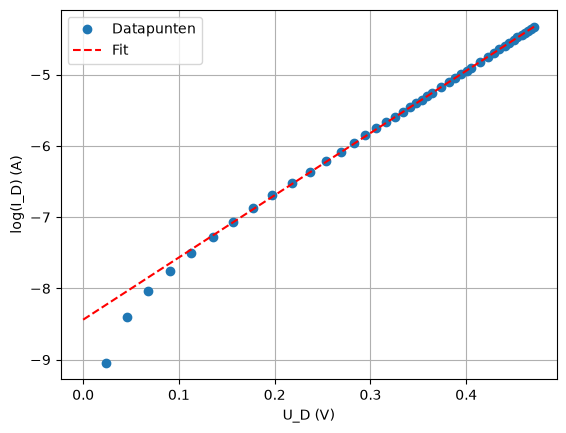

Log-lineaire controle voor waarde kb: 1.337000158563333e-23


In [3]:
#Data processing and analysis:
I_D = U_R/R_1
u_I_D = I_D*np.sqrt((u_U_R/U_R)**2 + (u_R_1/R_1)**2)

U_D = (R_3/(R_2+R_3))*U_bron - U_R    #vervolgens deze twee tegenover elkaar plotten met log(I_D) tegenover U_D
u_U_D = np.sqrt((f*u_U_bron)**2 + (U_bron*u_f)**2 + u_U_R**2)

mask = (U_D > 0.1)

gefilterde_U = U_D[mask]
gefilterde_I_log = np.log10(I_D[mask])

def func(x, a, b):
    return a*x + b
x_test = np.linspace(0, np.max(U_D), 100)
popt, pcov = curve_fit(func, gefilterde_U, gefilterde_I_log)
print(f'Gepaste parameters: a = {popt[0]}, b = {popt[1]}')
y_fit = func(x_test, *popt)
plt.plot(U_D, np.log10(I_D), 'o', label='Datapunten')
plt.plot(x_test, y_fit, 'r--', label='Fit')


plt.xlabel('U_D (V)')
plt.ylabel('log(I_D) (A)')  
plt.legend()
plt.grid()
plt.show()

BM = (np.log10(np.e) * 1.602e-19) / (popt[0] * 298 * 2.0)
print('Log-lineaire controle voor waarde kb:', BM)

**Describing the pattern in the processed data:**  


I_0 = 3.789e-09 A, b = 20.0028 +- 0.0276 1/V


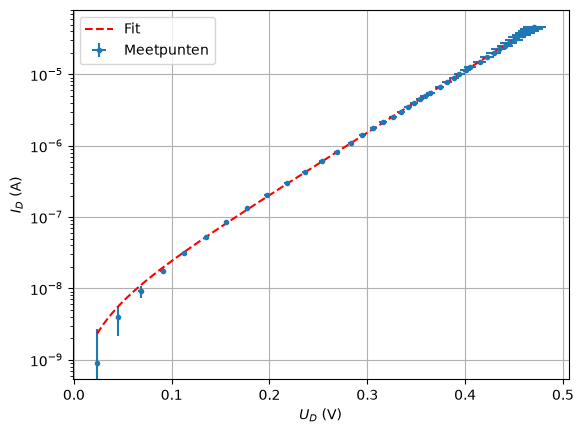

In [4]:
def diode(U, I_0, b):
    return I_0*(np.exp(b*U) - 1)

popt2, pcov2 = curve_fit(diode, U_D, I_D, p0=[3.6e-9, 20], sigma=u_I_D)
b_fit = popt2[1]
u_b = np.sqrt(pcov2[1,1])
print(f'I_0 = {popt2[0]:.3e} A, b = {b_fit:.4f} +- {u_b:.4f} 1/V')

x_fit = np.linspace(U_D.min(), U_D.max(), 200)
plt.errorbar(U_D, I_D, xerr=u_U_D, yerr=u_I_D, fmt='o', ms=3, label='Meetpunten')
plt.plot(x_fit, diode(x_fit, *popt2), 'r--', label='Fit')
plt.yscale('log')
plt.xlabel('$U_D$ (V)')
plt.ylabel('$I_D$ (A)')
plt.legend(); plt.grid(); plt.show()


In [5]:
#Calculations of e.a. measurement uncertainties, and providing final answers.
q, n, u_n, T, u_T = 1.602e-19, 2.0, 0.1, 298.0, 2.0                #q tussen absoluut strepen

k_B = q/(n*T*b_fit)
u_k_B = k_B*np.sqrt((u_b/b_fit)**2 + (u_n/n)**2 + (u_T/T)**2)
print(f'bijdragen: b {100*u_b/b_fit:.2f}%, n {100*u_n/n:.2f}%, T {100*u_T/T:.2f}%')
print(f'k_B = {k_B:.4e} +- {u_k_B:.2e} J/K')

k_B_lit = 1.380649e-23
if abs(k_B - k_B_lit) < 2*u_k_B:
    print('niet strijdig met de literatuurwaarde')
else:
    print('strijdig met de literatuurwaarde')

bijdragen: b 0.14%, n 5.00%, T 0.67%
k_B = 1.3438e-23 +- 6.78e-25 J/K
niet strijdig met de literatuurwaarde


# Discussion



De gevonden waarde ligt 2.7% onder de literatuurwaarde en is dus niet strijdig. De onzekerheid van 5% komt wel grotendeels van de idealiteitsfactor $n = 2.0 \pm 0.1$. De meting is dus niet door de elektronica begrensd maar door een tabelwaarde.

Twee systematische effecten zijn niet gecorrigeerd. De diodetak belast de spanningsdeler: $R_{th} = R_2 \parallel R_3 = 90.98\ \Omega$ is de weggelaten term $I_D R_{th}$ maximaal 4.2 mV, 0.9% van de hoogste $U_D$. Meenemen van die correctie verschuift $k_B$ naar 1.33e-23, dus verder van de literatuurwaarde af. Ook is $T$ niet gemeten maar aangenomen.

Het meten van de spanning over de diodetak rechtstreeks met de $5\frac{1}{2}$ digit DMM in plaats van hem uit $U_{bron}$ en de delerverhouding te berekenen zou een goede verbetering zijn van dit experiment. Dat haalt in één keer de dominante term $f\cdot u(U_{bron})$ uit $u(U_D)$, de bijdrage van $u(f)$, en de belastingscorrectie $I_D R_{th}$ weg.

# Conclusion

$k_B = (1.34 \pm 0.07)\times10^{-23}$ J/K, niet strijdig met de literatuurwaarde $1.380649\times10^{-23}$ J/K.